# Notebook 1 - GLCM + SVM
Klasifikasi motif batik pakai fitur tekstur GLCM, terus diklasifikasi pakai SVM.

Data dan split ngikutin punya tim (data_utils.py + split.csv). GLCM dihitung di tiap kanal RGB (32 level, jarak 1 & 2, 4 sudut, 5 properti) jadi total 120 fitur per gambar.

Hasil training disimpan ke `../models/svm_glcm.pkl`

In [1]:
import sys, json, time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from tqdm.auto import tqdm

from data_utils import load_split, load_images
from glcm_features import extract_features, feature_names

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

## Load data
Pakai load_split() dari data_utils biar splitnya sama kayak temen2 (70:30 stratified, seed 42)

In [2]:
df, kelas, label2id = load_split()
labels = json.load(open("../models/labels.json", encoding="utf-8"))
assert kelas == labels, "Urutan kelas harus sama dengan models/labels.json"

train_df = df[df["split"] == "train"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)
print(f"Train: {len(train_df)} gambar | Test: {len(test_df)} gambar | Kelas: {len(kelas)}")

Train: 686 gambar | Test: 295 gambar | Kelas: 20


In [3]:
t0 = time.perf_counter()
X_img_train, y_train = load_images(train_df, label2id)
X_img_test, y_test = load_images(test_df, label2id)
print(f"Memuat gambar: {time.perf_counter()-t0:.1f} s")
print("Train:", X_img_train.shape, "| Test:", X_img_test.shape)

Memuat gambar: 9.9 s
Train: (686, 224, 224, 3) | Test: (295, 224, 224, 3)


## Ekstraksi fitur GLCM
Tiap gambar diubah jadi 120 fitur tekstur. Waktunya dicatat karena diminta buat laporan.

In [4]:
t0 = time.perf_counter()
X_train = np.array([extract_features(img) for img in tqdm(X_img_train, desc="GLCM train")])
X_test = np.array([extract_features(img) for img in tqdm(X_img_test, desc="GLCM test")])
extract_sec = time.perf_counter() - t0
n_total = len(X_img_train) + len(X_img_test)
print(f"Dimensi fitur: {X_train.shape[1]}")
print(f"WAKTU EKSTRAKSI GLCM : {extract_sec:.2f} s total ({extract_sec/n_total*1000:.1f} ms/gambar)")

GLCM train:   0%|          | 0/686 [00:00<?, ?it/s]

GLCM test:   0%|          | 0/295 [00:00<?, ?it/s]

Dimensi fitur: 120
WAKTU EKSTRAKSI GLCM : 2.79 s total (2.8 ms/gambar)


## Training SVM
Fiturnya di-scale dulu pakai StandardScaler biar skalanya sama (SVM sensitif soal ini). C dan gamma dicoba beberapa kombinasi pakai grid search 3-fold CV. probability=True biar web nanti bisa nampilin persentase keyakinan.

In [5]:
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", probability=True, random_state=SEED)),
])
param_grid = {"svm__C": [0.1, 1, 10, 100], "svm__gamma": ["scale", 0.01, 0.001]}
gs = GridSearchCV(pipe, param_grid, cv=3, scoring="accuracy", n_jobs=-1, verbose=1)
t0 = time.perf_counter()
gs.fit(X_train, y_train)
train_sec = time.perf_counter() - t0
print(f"WAKTU PELATIHAN      : {train_sec:.2f} s")
print(f"Hyperparameter terbaik: {gs.best_params_} (CV acc {gs.best_score_:.4f})")

Fitting 3 folds for each of 12 candidates, totalling 36 fits


C:\Users\HP\Documents\untar\semester 3\machine learning\uas\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


WAKTU PELATIHAN      : 6.54 s
Hyperparameter terbaik: {'svm__C': 100, 'svm__gamma': 0.001} (CV acc 0.2056)


## Evaluasi di data test (30%)

In [6]:
model_svm = gs.best_estimator_
y_pred = model_svm.predict(X_test)
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="macro", zero_division=0)
rec = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
print(f"AKURASI   : {acc:.4f}")
print(f"PRECISION : {prec:.4f} (macro)")
print(f"RECALL    : {rec:.4f} (macro)")
print(f"F1-SCORE  : {f1:.4f} (macro)")
print(classification_report(y_test, y_pred, target_names=labels, zero_division=0))

AKURASI   : 0.1864
PRECISION : 0.1856 (macro)
RECALL    : 0.1876 (macro)
F1-SCORE  : 0.1782 (macro)
                   precision    recall  f1-score   support

       batik-bali       0.12      0.20      0.15        15
     batik-betawi       0.20      0.20      0.20        15
      batik-celup       0.20      0.33      0.25        15
batik-cendrawasih       0.14      0.13      0.14        15
     batik-ceplok       0.20      0.07      0.11        14
     batik-ciamis       0.19      0.27      0.22        15
    batik-garutan       0.18      0.20      0.19        15
  batik-gentongan       0.20      0.13      0.16        15
     batik-kawung       0.11      0.07      0.09        14
    batik-keraton       0.07      0.07      0.07        15
      batik-lasem       0.16      0.33      0.21        15
batik-megamendung       0.73      0.79      0.76        14
     batik-parang       0.43      0.20      0.27        15
 batik-pekalongan       0.13      0.13      0.13        15
   batik-prian

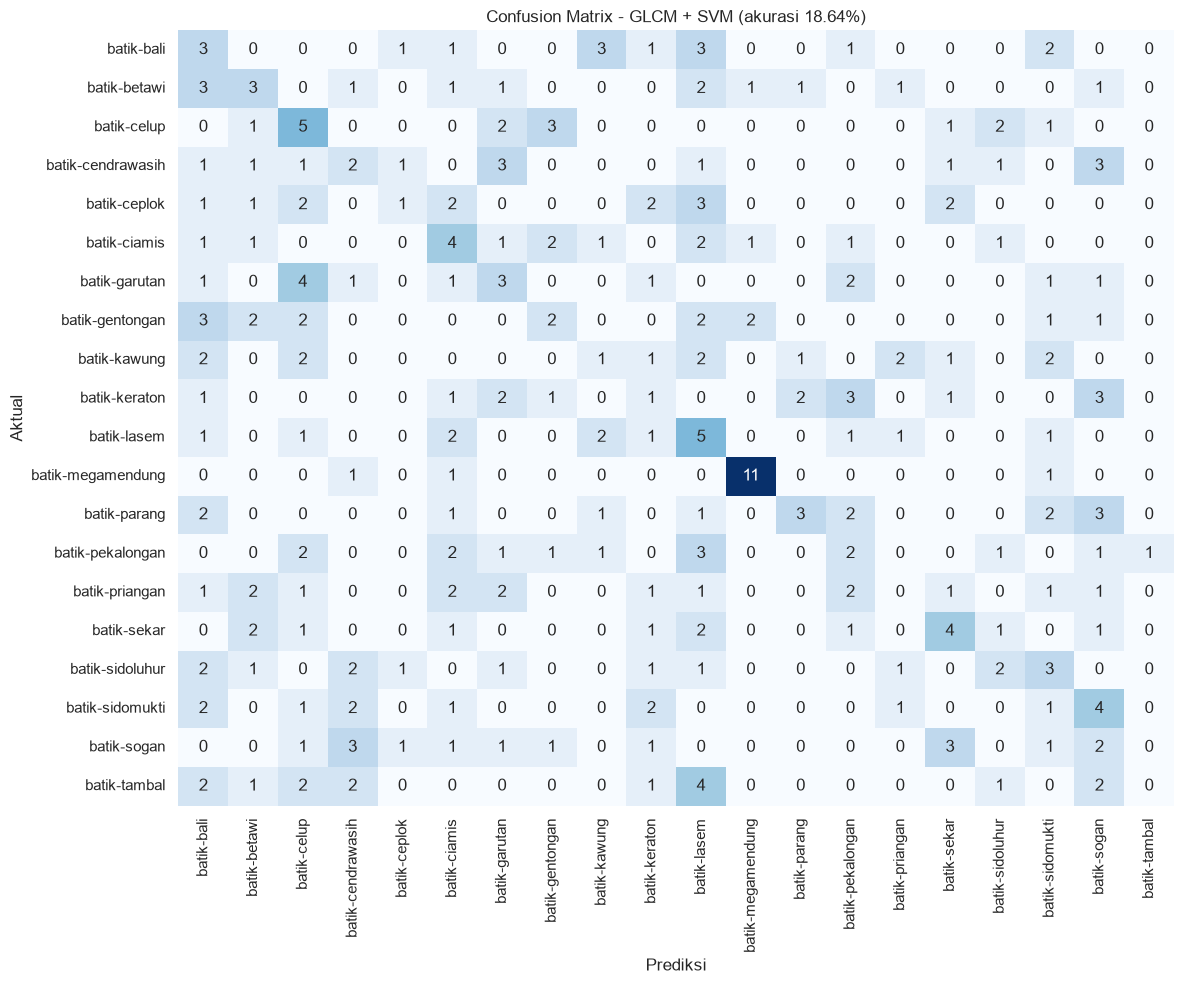

In [7]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels, cbar=False)
plt.xlabel("Prediksi"); plt.ylabel("Aktual")
plt.title(f"Confusion Matrix - GLCM + SVM (akurasi {acc:.2%})")
plt.xticks(rotation=90); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()

## Save model
Model sama metriknya disimpan. metrics json nya buat bahan laporan.

In [8]:
joblib.dump(model_svm, "../models/svm_glcm.pkl")
metrics = {
    "model": "GLCM + SVM (RBF)",
    "accuracy": float(acc),
    "precision_macro": float(prec),
    "recall_macro": float(rec),
    "f1_macro": float(f1),
    "feature_extraction_sec": float(extract_sec),
    "feature_extraction_ms_per_image": float(extract_sec / n_total * 1000),
    "training_sec": float(train_sec),
    "best_params": {k: (v if isinstance(v, str) else float(v)) for k, v in gs.best_params_.items()},
    "cv_best_accuracy": float(gs.best_score_),
    "n_train": int(len(y_train)), "n_test": int(len(y_test)),
    "labels": labels,
    "confusion_matrix": cm.tolist(),
    "classification_report": classification_report(y_test, y_pred, target_names=labels, output_dict=True, zero_division=0),
}
with open("../models/metrics_glcm_svm.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)
print("Tersimpan: models/svm_glcm.pkl & models/metrics_glcm_svm.json")

Tersimpan: models/svm_glcm.pkl & models/metrics_glcm_svm.json
